# Progetto di Machine Learning

## Previsione del prezzo unitario degli immobili (Real Estate Valuation,UCI)
(Arshita Mahajan)
(ADIF) (199048)

## 1. Selezione e analisi del dataset

### 1.1 Descrizione del dataset
Il progetto ha l'obiettivo di stimare prezzo unitario degli immobili residenziali con diversi algoritmi di regressione. Ho scelto il dataset **Real Estate Valuation**, preso dall'UCI Machine Learning Repository.

*Fonte:* https://archive.ics.uci.edu/dataset/477/real+estate+valuation+data+set

I dati riguardano compravendite immobiliari nel distretto di Sindian, a Nuova Taipei (Taiwan), tra agosto 2012 e luglio 2013.

Dataset contiene 414 osservazioni e 8 colonne: 6 variabili esplicative, 1 variabile target e 1 colonna identificativa.

La variabile target 'Y house price of unit area' che rappresenta prezzo immobiliare per unità di superficie, espressa in 10.000 di NTD per ping. Un ping corrisponde a circa 3.3 m². Valore non rappresenta quindi il prezzo per metro quadrato.

Poi ho escluso la colonna 'No' perchè identifica le osservazioni e non descrive nessuna caratteristica.

### Perché ho scelto questo dataset? E domande di ricerca
Ho scelto questo dataset perché mi interessa molto il settore immobiliare e volevo scoprire come l'analisi dei dati e tecniche di Machine learning possono essere utilizzate per valutare proprietà immobiliari.
Poi, in particolare, è interessante esplorare il ruolo dell'accessibilità ai trasporti pubblici e dalla disponibilità di servizi nelle vicinanze.

**Domanda principale**:
In che misura la distanza dalla stazione MRT, il numero di negozi di prossimità e la posizione geografica sono associati ai prezzi immobiliari?

Il progetto unisce quindi analisi delle relazioni fra variabili al confronto delle prestazioni predittive dei modelli, senza interpretare le associazioni osservate come rapporti di causa-effetto.

### 1.2 Caricamento e struttura del datatset
Il dataset viene importato tramite la libreria Pandas. Si procede quindi alla visualizzazione delle prime osservazioni e alla verifica delle dimesioni e dei tipi di dati.

In [ ]:
import os
import pandas as pd
from google.colab import files

# Caricamento del dataset (se il file non è presente nella sessione Colab, viene chiesto di caricarlo)
path = "/content/Real estate valuation data set.xlsx"
if not os.path.exists(path):
    print("Carica il file del dataset UCI (Real estate valuation data set.xlsx)")
    caricato = files.upload()
    path = "/content/" + next(iter(caricato))

df = pd.read_excel(path)

# Visualizzazione delle prime cinque osservazioni
display(df.head())

# Dimensioni del dataset
print("Dimensioni del dataset:", df.shape)

# Informazioni sulla struttura del dataset
df.info()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500000,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833333,5.0,390.56840,5,24.97937,121.54245,43.1


Dimensioni del dataset: (414, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 8 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   No                                      414 non-null    int64  
 1   X1 transaction date                     414 non-null    float64
 2   X2 house age                            414 non-null    float64
 3   X3 distance to the nearest MRT station  414 non-null    float64
 4   X4 number of convenience stores         414 non-null    int64  
 5   X5 latitude                             414 non-null    float64
 6   X6 longitude                            414 non-null    float64
 7   Y house price of unit area              414 non-null    float64
dtypes: float64(6), int64(2)
memory usage: 26.0 KB


L'analisi della struttura mostra che ci sono 414 osservazioni e 8 colonne.
Tutte le variabili sono di tipo numerico. Sei colonne sono indicate come 6 float64 e 2 int64.
Ogni colonna ha 414 valori non nulli, quindi non ci sono valori mancanti in questa prima verifica.
La colonna no è un identicativo e non sarà inclusa tra le variabili predittive.

###1.3 Statistiche descrittive

Ho calcolato le principali statistiche descrittive delle variabili numeriche perché mi aiuterà a capire la posizione centrale, la dispersione e l'intervallo dei valori osservati nel dataset.

In [ ]:
# Statistiche descrittive delle variabili numeriche
display(df.describe())

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
count,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000
mean,207.500000,2013.148953,17.712560,1083.885689,4.094203,24.969030,121.533361,37.980193
std,119.655756,0.281995,11.392485,1262.109595,2.945562,0.012410,0.015347,13.606488
min,1.000000,2012.666667,0.000000,23.382840,0.000000,24.932070,121.473530,7.600000
25%,104.250000,2012.916667,9.025000,289.324800,1.000000,24.963000,121.528085,27.700000
50%,207.500000,2013.166667,16.100000,492.231300,4.000000,24.971100,121.538630,38.450000
75%,310.750000,2013.416667,28.150000,1454.279000,6.000000,24.977455,121.543305,46.600000
max,414.000000,2013.583333,43.800000,6488.021000,10.000000,25.014590,121.566270,117.500000


#Interpretazione delle statistiche descrittive
Il prezzo medio per unità di superficie è di circa 37,98 (in unità di 10.000 NTD per ping). I valori vanno da 7,60 a 117,50. Questo ampio intervallo ci fa pensare di guardare da vicino la distribuzione del prezzo.

L'età media degli immobili è di 17,71 anni. La mediana,invece, è di circa 16,10 anni.

La distanza media dalla stazione MRT più vicina è di circa 1.083,89 metri. La mediana, però, è molto più bassa: 492,23 metri. Questa differenza spiega che la distribuzzione è assimetrica. Alcune transazioni riguardano immobili molto più lontani dalla stazione rispetto alla maggior parte.

### 1.4 Analisi esplorativa dei dati(EDA)
Questa analisi mi permette di esaminare graficamente la distribuzione delle variabili e individuare eventuali caratteristiche rilevanti per la costruzione dei modelli di regressione.
### Distribuzione della variabile Target
Si utilizza un istogramma per analizzare la distribuzione dei prezzi immobiliari e identificare eventuali valori estremi.

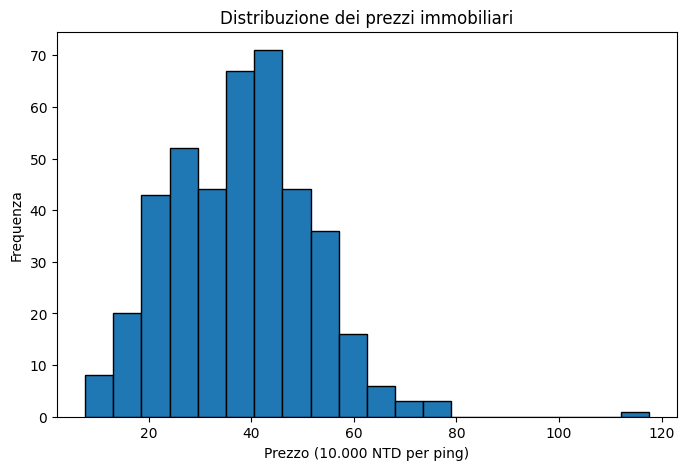

In [ ]:
import matplotlib.pyplot as plt
# Istogramma della variabile target
plt.figure(figsize=(8, 5))
plt.hist(df["Y house price of unit area"],
         bins=20,
         edgecolor="black")
plt.title("Distribuzione dei prezzi immobiliari")
plt.xlabel("Prezzo (10.000 NTD per ping)")
plt.ylabel("Frequenza")
plt.show()


###Interpretazione dell'Istogramma
Attraverso l'istogramma, ho notato che la maggior parte dei prezzi per unità di superficie si concentra circa tra 20 e 60, in unità di 10.000 NTD per ping. La distribuzione mostra una coda verso destra. Alcuni valori, che sono particolarmente elevati, come 117,5, meritano un uleteriore controllo.  

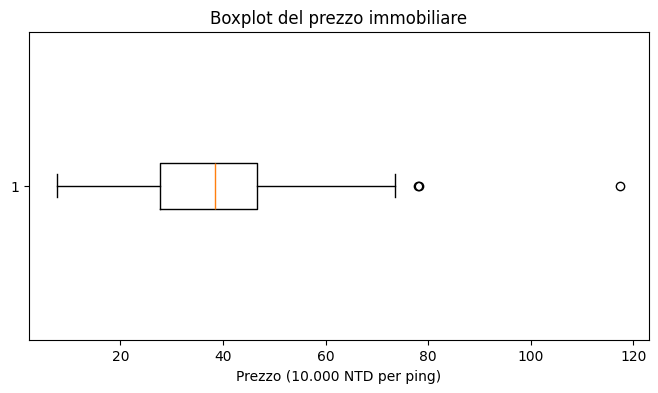

In [ ]:
#Boxplot della variabile target
plt.figure(figsize=(8,4))
plt.boxplot(df["Y house price of unit area"],vert=False)
plt.title("Boxplot del prezzo immobiliare")
plt.xlabel("Prezzo (10.000 NTD per ping)")
plt.show()

### Interpretazione del Boxplot
Qui noto che il 50% centrale dei prezzi si trova tra 27,70 che è il primo quartile e 46,60 che è il terzo quartile, e la mediana è 38,45. Il grafico mostra alcuni punti fuori dalla norma nella parte alta del grafico.
Analizzando l'IQR, abbiamo individuato tra valori che potrebbe essere considerati anomali: 78.0, 78.3 e 117.5. Notiamo che 78.0 e 78.3 sono molto vicini, quasi sovrapposti, e questo può rendere difficile distinguerli nel grafico.
Questi valori non sono errori. Possono rispecchiare caratteristiche reali degli immobili, come una superficie molto grande o una posizione particolare. Per questo, non li elimino subito. Li tengo d'occhio durante la fase di preparazione dei dati, per capire se hanno un senso o se invece devono essere rivisionati.

### Distribuzione della distanza dalla stazione MRT
Per approfondire la distribuzione della distanza MRT più vicina utilizzo un istogramma e un boxplot. L'istogramma mostra la frequenza dei diversi valori e il boxplot viene utilizzato di osservare la dispersione e individuare potenziali valori estremi. Questo mi aiuta a comprendere meglio la variabile prima della preparazione dei dati.

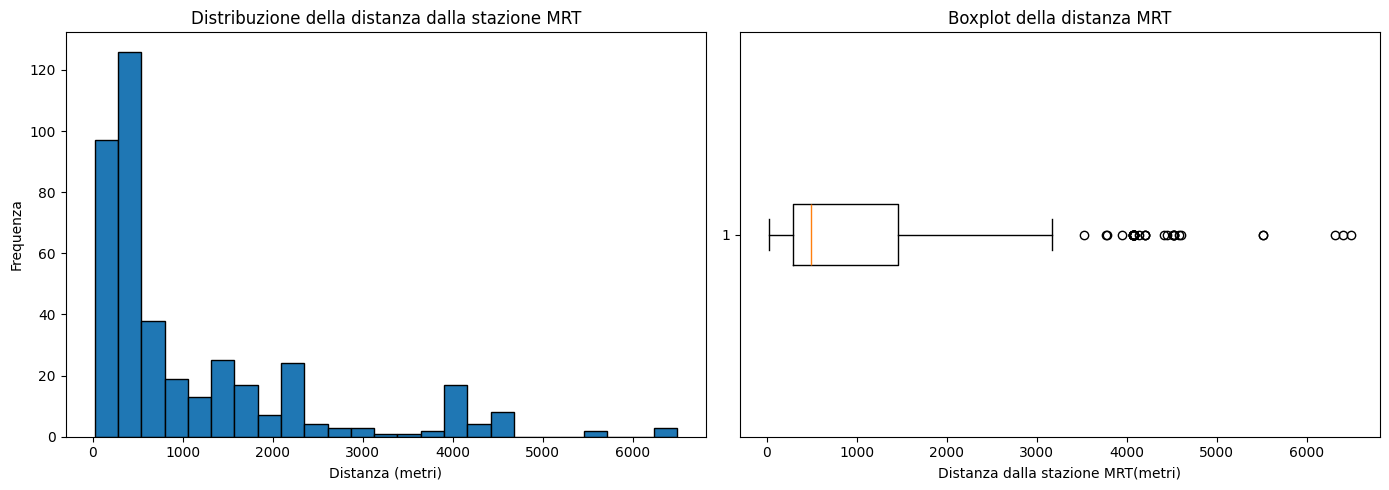

In [ ]:
# Distribuzione della distanza dalla stazione MRT
mrt_distance= df["X3 distance to the nearest MRT station"]
fig,axes = plt.subplots(1,2,figsize=(14,5))

#Istogramma
axes[0].hist(mrt_distance,bins=25,edgecolor="black")
axes[0].set_title("Distribuzione della distanza dalla stazione MRT")
axes[0].set_xlabel("Distanza (metri)")
axes[0].set_ylabel("Frequenza")

#Boxplot
axes[1].boxplot(mrt_distance,vert=False)
axes[1].set_title("Boxplot della distanza MRT")
axes[1].set_xlabel("Distanza dalla stazione MRT(metri)")

plt.tight_layout()
plt.show()



### Interpretazione
Ho osservato che la distribuzione della distanza dalla stazioen MRT è assimetrica a destra. La maggior parte degli immobili si trova relativamente vicino a una stazione, invece un numero minore degli immobili presenta distanza molto elevate.

Boxplot evidenzia diversi potenziali valori anomali oltre il baffo superiore, alcuni dei quali superano i 6.000 metri.
Queste osservazioni non sono errori perché rappresentano immobili realmente situati lontani dai mezzi pubblici.
E proprio per questo motivo, ho deciso di non eliminare questi valori ma di valutarli e conservarli durante la preparazione dei dati e costruzione dei modelli.

# Analisi delle relazioni tra variabili
### Scatterplot_1: Relazione tra distanza della stazione MRT e prezzo immobiliare

In questo grafico analizzo relazione distanza dalla stazioen MRT più vicina e prezzo degli immobili.

Utilizzo un grafico a dispersione per osservare come varia il prezzo in base alla distanza e individuare eventuali tendenze nei dati.

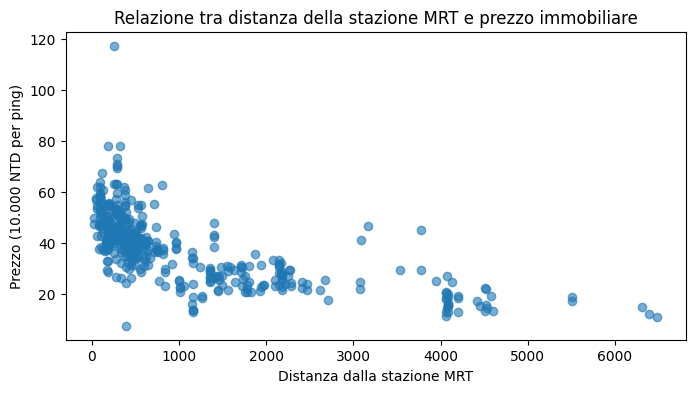

In [ ]:
plt.figure(figsize=(8,4))
plt.scatter(df["X3 distance to the nearest MRT station"],
            df["Y house price of unit area"],
            alpha= 0.6
)
plt.title("Relazione tra distanza della stazione MRT e prezzo immobiliare")
plt.xlabel("Distanza dalla stazione MRT")
plt.ylabel("Prezzo (10.000 NTD per ping)")
plt.show()

### Scatterplot_2: Relazione tra numero di negozi di prossimità e prezzo immobiliare

In questo grafico, la relazione tra il numero di negozi di prossimità e prezzo degli immobili.

Grafico mi aiuterà di confrontare bene i prezzi per i diversi numeri di negozi e osservare eventuali tendenze o differenze.

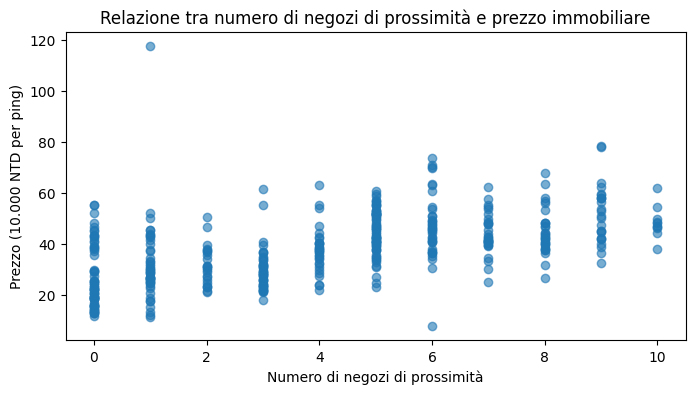

In [ ]:
# Relazione tra negozi di prossimità e prezzo immobiliare
plt.figure(figsize=(8,4))
plt.scatter(df["X4 number of convenience stores"],
            df["Y house price of unit area"],
            alpha= 0.6
)
plt.title("Relazione tra numero di negozi di prossimità e prezzo immobiliare")
plt.xlabel("Numero di negozi di prossimità")
plt.ylabel("Prezzo (10.000 NTD per ping)")
plt.show()

### Interpretazione dello scatterplot_1 Distanza dalla MRT
Il grafico a dispersione evidenzia una relazione tendenzialmente negativa tra la distanza dalla stazione MRT più vicina e il prezzo immobiliare.
Gli immobili situati a distanza minori presentano generalmente prezzi più elevati, mentre all'aumentare della distanza si osserva una tendenza alla diminuzione dei prezzi.
La relazione non è perfetta, suggerendo che anche altre caratteristiche possano influenzare il prezzo degli immobili.

### Interpretazione dello scatterplot_2 negozi di prossimità
Il grafico mostra una relazione tendenzialmente positiva tra il numero di negozi di prossimità e il prezzo immobiliare.
Gli immobili con un maggior numero di negozi nelle vicinanze tendono a presentare prezzi più elevati. Tuttavia, la presenza di alcune osservazioni con prezzi particolarmente alti, anche in corrispondenza di pochi negozi, evidenzia che la relazione non è uniforme e che altri fattori potrebbero influenzare il prezzo.

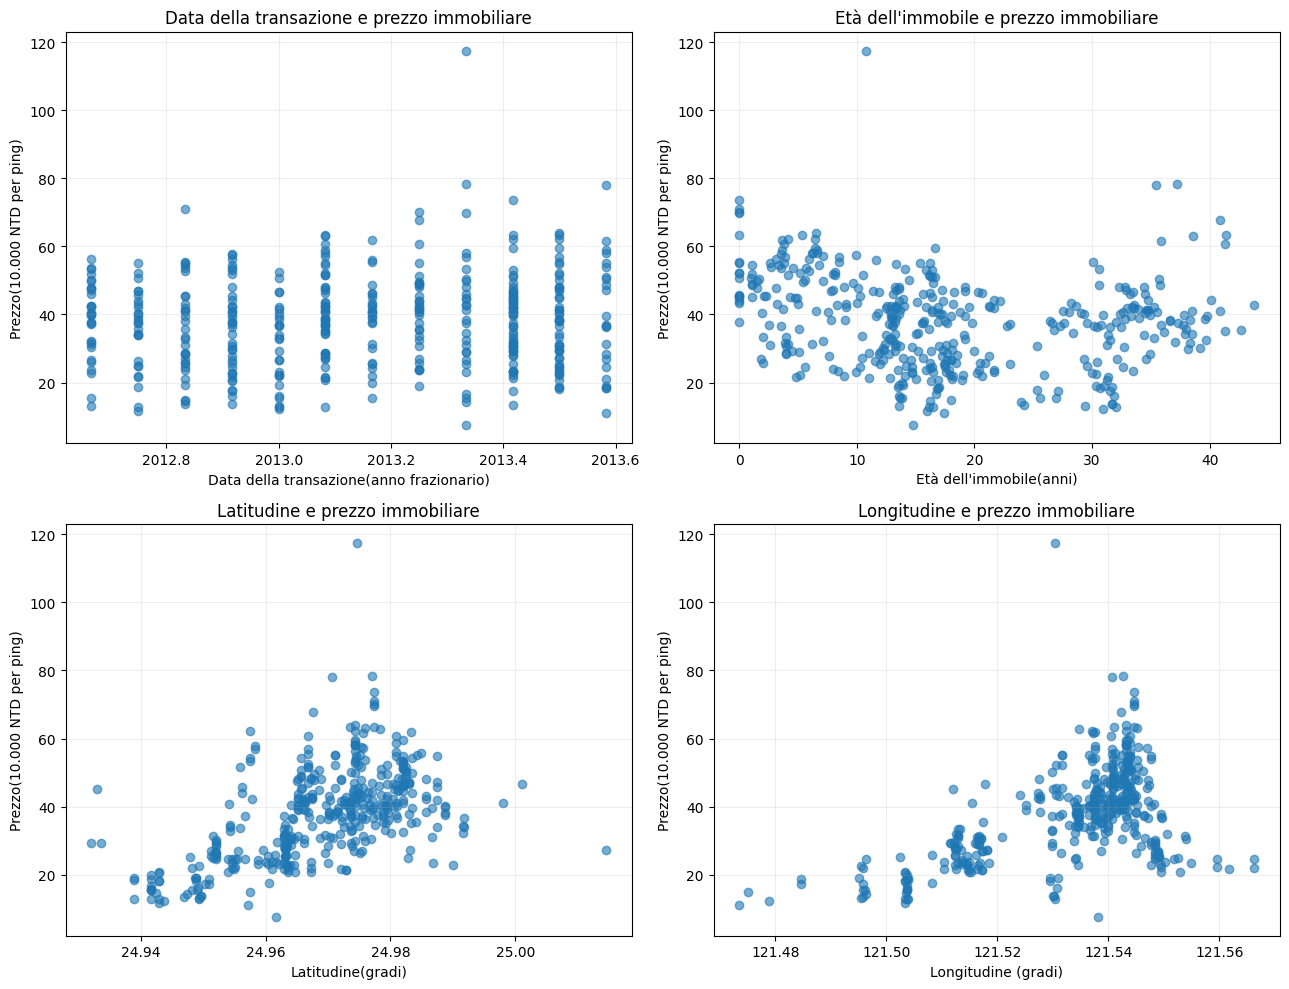

In [ ]:
#Scatterplot delle quattro variabili esplicativi non ancora rappresentate
features_to_plot= [
    ("X1 transaction date","Data della transazione(anno frazionario)","Data della transazione"),
    ("X2 house age","Età dell'immobile(anni)","Età dell'immobile"),
    ("X5 latitude","Latitudine(gradi)","Latitudine"),
    ("X6 longitude","Longitudine (gradi)","Longitudine")
]
target= "Y house price of unit area"

fig,axes= plt.subplots(2,2,figsize=(13,10))
for ax, (column,xlabel,title)in zip(axes.flat,features_to_plot):
  ax.scatter(df[column],df[target],alpha=0.6)
  ax.set_title(f"{title} e prezzo immobiliare")
  ax.set_xlabel(xlabel)
  ax.set_ylabel("Prezzo(10.000 NTD per ping)")
  ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Interpretazione
Dai grafici posso osservare relazioni tra caratteristiche degli immobili e prezzo.
- Data della transazione: non si nota una relazione chiara tra data e prezzo. I prezzi variano molto nel tempo.
- Età dell'immobile: in generale, prezzi sembrano più bassi per gli immobili tra 10 e 20 anni. Ma non è una regola fissa ci sono molte eccezioni e la relazione non è perfettamente lineare.
- Latitudine e Longitudine: posizione geografica ha un impatto chiaro sui prezzi. Alcune zone hanno prezzi medio più alti, altri più bassi anche se all'interno di una stessa zona ci sono differenze significative.

In sintesi, grafici presenta il prezzo dipende da diversi fattori: caratteristiche dell'immobile e sua posizione. Queste osservazioni sono utili per capire meglio i dati prima di iniziare a costruire i modelli di Machine Learning.

### Distribuzione geografica dei prezzi immobiliari

Per approfondire il ruolo della posizione geografica, rappresento le osservazioni utlizzando latitudine e longitudine e distinguo i punti al prezzo unitario. Questa visualizzazione permette di esplorare eventuali pattern geografici nei prezzi. I punti rappresentano gli immobili del dataset, non le posizioni delle stazioni MRT

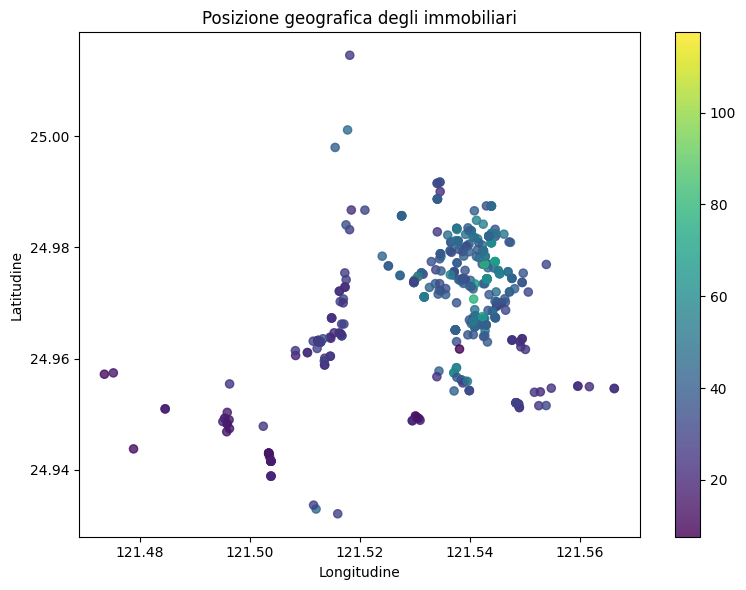

In [ ]:
# Posizione geografica degli immobili, colorato in base al prezzo
fig, ax = plt.subplots(figsize=(8,6))
point= ax.scatter(
    df["X6 longitude"],
    df["X5 latitude"],
    c=df["Y house price of unit area"],
    cmap="viridis",
    alpha=0.8,
    s=35
)
ax.set_title("Posizione geografica degli immobiliari")
ax.set_xlabel("Longitudine")
ax.set_ylabel("Latitudine")
colorbar= fig.colorbar(point,ax=ax)
plt.tight_layout()
plt.show()

### Interpretazione
Dal grafico, osservo che molti immobili si concentrano nella zona intorno alla longitudine 121.54 e latitudine 24.97 e 24.98. In questa zona, sono presenti i prezzi relativamente più alti indicati dai colori più chiari.

Nelle altre zone i punti sono più dispersi e osservano prezzi poù bassi.

Questo mi suggerisce che posizione geografica può essere collegata al prezzo degli immobili. La distribuzione dei punti mostra che prezzi non sono uguali in tutte le zone del dataset.

### Analisi delle correlazioni tra le variabili

In questa fase, calcolo prima le correlazioni di Pearson tra ciascuna variabile e prezzo unitario. In seguito, esamino anche la matrice di correlazione tra le *sei variabili esplicative*, per capire quali predittori possono contenere informazioni sovrapposte.

In [ ]:

# Calcolo delle correlazioni escludendo l'identificativo
correlation_matrix = df.drop(columns=["No"]).corr()

# Correlazioni con il prezzo immobiliare
display(correlation_matrix["Y house price of unit area"])


,Y house price of unit area
X1 transaction date,0.087529
X2 house age,-0.210567
X3 distance to the nearest MRT station,-0.673613
X4 number of convenience stores,0.571005
X5 latitude,0.546307
X6 longitude,0.523287
Y house price of unit area,1.000000


### Visualizzazione delle correlazioni con il prezzo

Per facilitare il confronto tra le correlazioni di Pearson delle singole variabili esplicative con il prezzo, rappresento i coefficienti mediante un grafico a barre orrizontali. Il grafico mi permette di confrontare bene la direzione e intensità delle associazioni lineari.

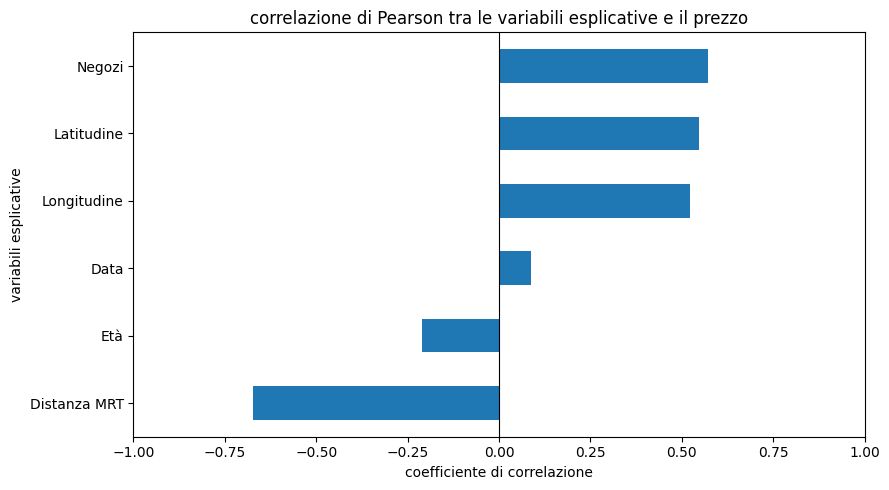

In [ ]:
#Correlazione di ciascun predittore con il prezzo
corr_target = correlation_matrix["Y house price of unit area"].drop("Y house price of unit area")
labels_map={
    "X1 transaction date": "Data",
    "X2 house age": "Età",
    "X3 distance to the nearest MRT station": "Distanza MRT",
    "X4 number of convenience stores": "Negozi",
    "X5 latitude": "Latitudine",
    "X6 longitude":"Longitudine"
}
corr_target = corr_target.rename(index=labels_map).sort_values()

fig, ax = plt.subplots(figsize=(9,5))
corr_target.plot(kind="barh",ax=ax)
ax.axvline(0,color="black",linewidth=0.8)
ax.set_xlim(-1,1)
ax.set_title("correlazione di Pearson tra le variabili esplicative e il prezzo")
ax.set_xlabel("coefficiente di correlazione")
ax.set_ylabel("variabili esplicative")
plt.tight_layout()
plt.show()


### Heatmap
In questa sezione utilizzo una heatmap per visualizzare le correlazioni tra tutte le variabili esplicative e confrontarle tra loro. I colori e i valori nella matrice permettono di osservare la direzione e l'intensità delle relazioni lineari tra le variabili, aiutando a individuare quelle che possono essere maggiormente collegate tra loro.

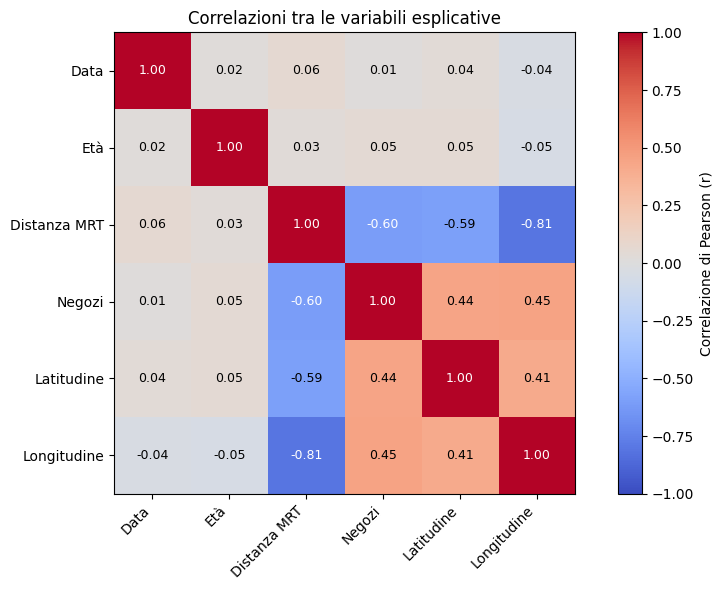

In [ ]:
# Heatmap delle correlazioni tra le sole variabili esplicative
features_corr = df.drop(columns=["No", "Y house price of unit area"]).corr()
feature_labels = ["Data", "Età", "Distanza MRT", "Negozi", "Latitudine", "Longitudine"]

fig, ax = plt.subplots(figsize=(9, 6))
heatmap = ax.imshow(features_corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(feature_labels)), labels=feature_labels, rotation=45, ha="right")
ax.set_yticks(range(len(feature_labels)), labels=feature_labels)

# Valori numerici all'interno delle celle
for i in range(len(feature_labels)):
    for j in range(len(feature_labels)):
        ax.text(j, i, f"{features_corr.iloc[i, j]:.2f}",
                ha="center", va="center", fontsize=9,
                color="white" if abs(features_corr.iloc[i, j]) > 0.60 else "black")

fig.colorbar(heatmap, ax=ax, label="Correlazione di Pearson (r)")
ax.set_title("Correlazioni tra le variabili esplicative")
plt.tight_layout()
plt.show()

**Interpretazione delle correlazioni**
La distanza dalla stazione MRT e il prezzo unitario sono collegati in modo negativo(r=-0,674), come si vede nello scatterplot.
Il numero di negozi è collegato positivamente(r=0,571), così come la latitudine(r=0,546) e la longitudine(r=0,523).
L'età dell'immobile è leggermente collegata in modo negativo (r=-0,211). La data della transazione invece mostra una leggera connessione lineare(r=0,088).
Se parliamo della heatmap,quello evidenzia anche relazioni tra i predittori. In particolare, distanza MRT e longitudine sono molto collegate in modo negativo(r≈ -0,806) e numero di negozi(r≈ -0,603).

Queste connessioni indicano che possono essere multicollinearità, rendendo difficile interpretare singolarmente i coefficienti della regressione multipla.
Le correlazioni mostrano solo legami statistici, non dimostrano causa ed effetto.

###Selezione delle variabili esplicative

Per la previsione del prezzo immobiliare si considerano le sei variabili esplicative disponibili, che descrivono le caratteristiche temporali, strutturali e geografiche degli immobili, nonché l'accessibilità ai trasporti e ai servizi.

La colonna `No` viene esclusa poiché rappresenta esclusivamente un identificativo delle osservazioni e non fornisce informazioni utili alla previsione del prezzo.

# 2. Pulizia e Preparazione dei dati

###2.1 Verifica dei valori mancanti e duplicati

In [ ]:
#Verifica dei valori mnancanti
print("Valori mancanti per colonna:")
print(df.isnull().sum())

#Verifica delle osservazioni duplicate (escludendo l'ID)
print("\n Numero di osservazioni duplicati:")
print(df.drop(columns=["No"]).duplicated().sum())

Valori mancanti per colonna:
No                                        0
X1 transaction date                       0
X2 house age                              0
X3 distance to the nearest MRT station    0
X4 number of convenience stores           0
X5 latitude                               0
X6 longitude                              0
Y house price of unit area                0
dtype: int64

 Numero di osservazioni duplicati:
0


### Interpretazione dei risultati
Il controllo della qualità dei dati non evidenza valori mancanti nelle 414 osservazioni. Inoltre, escludendo la colonna identificativo No, non risulta osservazioni duplicate.
 Pertanto non sono necessari interventi di imputazione dei valori mancanti o eliminazione di duplicati.

### 2.2 Analisi dei valori anomali

In [ ]:
target= "Y house price of unit area"
Q1 = df[target].quantile(0.25)
Q3= df[target].quantile(0.75)
IQR = Q3 - Q1

#Calcolo dei limiti
lower_limit= Q1- 1.5 * IQR
upper_limit= Q3 + 1.5 * IQR
print("Limite Inferiori:", lower_limit)
print("Limite Superiori:", upper_limit)

#Identificazione dei potenziali outlier
outliers= df[
    (df[target]< lower_limit) |
    (df[target]> upper_limit)
]
display(outliers)

Limite Inferiori: -0.6500000000000021
Limite Superiori: 74.95


,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
220,221,2013.333333,37.2,186.5101,9,24.97703,121.54265,78.3
270,271,2013.333333,10.8,252.5822,1,24.97460,121.53046,117.5
312,313,2013.583333,35.4,318.5292,9,24.97071,121.54069,78.0


In [ ]:
# Analisi dei valori anomali nella distanza MRT
feature= "X3 distance to the nearest MRT station"

Q1_mrt= df[feature].quantile(0.25)
Q3_mrt= df[feature].quantile(0.75)
IQR_mrt= Q3_mrt - Q1_mrt

# Calcolo dei limiti IQR
lower_mrt = Q1_mrt - 1.5 * IQR_mrt
upper_mrt = Q3_mrt + 1.5 * IQR_mrt
print("Limit Inferiore:", lower_mrt)
print("Limit Superiore:", upper_mrt)

# Identificazione dei potenziali outlier
outliers_mrt = df[
    (df[feature] < lower_mrt) |
    (df[feature] > upper_mrt)
]
print("Numero di potenziali outlier:",len(outliers_mrt))
display(outliers_mrt.head(10))

Limit Inferiore: -1458.1065000000003
Limit Superiore: 3201.7103
Numero di potenziali outlier: 37


,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
8,9,2013.500000,31.7,5512.038,1,24.95095,121.48458,18.8
30,31,2013.500000,25.9,4519.690,0,24.94826,121.49587,22.1
35,36,2013.500000,13.9,4079.418,0,25.01459,121.51816,27.3
40,41,2013.000000,13.6,4082.015,0,24.94155,121.50381,15.9
41,42,2013.500000,16.8,4066.587,0,24.94297,121.50342,18.2
48,49,2013.416667,24.2,4605.749,0,24.94684,121.49578,13.4
49,50,2012.666667,29.4,4510.359,1,24.94925,121.49542,13.2
58,59,2013.500000,30.3,4510.359,1,24.94925,121.49542,22.6
73,74,2013.166667,13.8,4082.015,0,24.94155,121.50381,20.0
87,88,2013.583333,16.9,4066.587,0,24.94297,121.50342,18.3


In [ ]:
feature_age= "X2 house age"
Q1_age= df[feature_age].quantile(0.25)
Q3_age= df[feature_age].quantile(0.75)
IQR_age= Q3_age - Q1_age

#Calcolo dei limiti IQR
lower_age= Q1_age - 1.5 * IQR_age
upper_age= Q3_age + 1.5 * IQR_age
print("Limit Inferiore:", lower_age)
print("Limit Superiore:", upper_age)

#Identificazione dei potenziali outlier
outliers_age= df[
    (df[feature_age] < lower_age)|
    (df[feature_age]>upper_age)
]
print("Numero di potenziali outlier:",len(outliers_age))
display(outliers_age)

Limit Inferiore: -19.6625
Limit Superiore: 56.8375
Numero di potenziali outlier: 0


,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area


In [ ]:
# verifica dei valori dei negozi di prossimità
Stores= df["X4 number of convenience stores"]
print("Valore minimo:",Stores.min())
print("Valore massimo:",Stores.max())

#Frequenza dei valori osservati
display(Stores.value_counts().sort_index())

Valore minimo: 0
Valore massimo: 10


,count
X4 number of convenience stores,
0,67
1,46
2,24
3,46
4,31
5,67
6,37
7,31
8,30


In [ ]:
#Columns to check
Columns_check=[
    "X1 transaction date",
    "X5 latitude",
    "X6 longitude"
]
for column in Columns_check:
  print("\n Variable:", column)
  print("Minimo:",df[column].min())
  print("Massimo:",df[column].max())


 Variable: X1 transaction date
Minimo: 2012.6666667
Massimo: 2013.5833333

 Variable: X5 latitude
Minimo: 24.93207
Massimo: 25.01459

 Variable: X6 longitude
Minimo: 121.47353
Massimo: 121.56627


### Interpretazione dell'analisi dei valori anomali
L'analisi mediante il metodo IQR ha individuato 3 potenziali valori anomali nel prezzo unitario e 37 nella distanza di MRT, mentre non sono stati rilevati nell'età degli immobili.
Per le altre variabili sono stati verificati valori massimi e minimi, senza riscontrare evidenti incongruenze sulla base di questo controllo preliminiare.
I tre prezzi 78.0,78.3 e 117.5. Le osservazioni corrispondenti si trovano tutti entro circa 320 metri dalla MRT, ma hanno una differenza per età e numero di negozi nelle vicinanze. Non ci sono elementi sufficienti per classificarle come errori di registrazione.

Questa analisi IQR è descrittiva ed è svolta sul dataset completo prima della suddivisione. Non escludo automaticamente questi valori perché possono rappresentare immobili reali.

### 2.3 Verifica delle variabili categoriali e codifica
Le sei variabili esplicative sono già numeriche, la data della transazione è rappresentata come valore numerico frazionario, l'età e distanza sono misure numeriche, numero di negozio è un conteggio e latitudine e longitudine sono coordinate geografiche. Il dataset non contiene variabili categoriali che richiedono una codifica one-hot encoding o etichette; quindi non ho applicato la trasformazione di questo tipo.

### 2.4 Preparazione delle variabili e suddivisione dei dati
Prima di qualsiasi addestramento, separo le variabili esplicative X, che sono sei colonne senza *No*, dalla variabile target Y.

Poi divido il dataset in 80% training set e 20% test set. Il test set viene messo da parte e sarà usato soltanto nella valutazione finale.

In [ ]:
#Separazione delle variabili esplicative e della target
X= df.drop(columns=["No","Y house price of unit area"])
Y= df["Y house price of unit area"]

#Verifica delle dimensioni
print("Dimensioni di X:",X.shape)
print("Dimensioni di Y:", Y.shape)

from sklearn.model_selection import train_test_split

#Suddivisione in training set e test set
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size= 0.2,
    random_state=42
)
#Verifica delle dimensioni
print("X_train:",X_train.shape)
print("X_test:",X_test.shape)
print("Y_train:",Y_train.shape)
print("Y_test:",Y_test.shape)


Dimensioni di X: (414, 6)
Dimensioni di Y: (414,)
X_train: (331, 6)
X_test: (83, 6)
Y_train: (331,)
Y_test: (83,)


### Interpretazione
La suddivisione del dataset in training e test è stata fatta con un rapporto 80/20, per una questione di equilibrio.
Il dataset è piuttosto piccolo (414 osservazioni), quindi ho preferito evitare una divisione troppo asimmetrica. Con un 90/10 il test set avrebbe avuto solo circa 41 osservazioni e questo avrebbe reso le metriche troppo instabili. Allo stesso tempo, una suddivisione 70/30 avrebbe lasciato al training circa 290 osservazioni, un numero che mi sembra troppo basso per un buon addestramento. Ho quindi scelto 80/20, che è un punto di equilibrio migliore: 331 osservazioni per il training e 83 per il test.

Nella fase 4 la cross-validation a 5 fold verrà applicata soltanto al training set: ogni fold addestrerà il modello su circa 265 immobili e lo valuterà su circa 66. Il parametro *random_state=42* rende la suddivisione riproducibile.

Il prezzo medio è simile nei due insiemi (38,39 in training, 36,34 in test), ma i tre valori anomali di prezzo (78,0, 78,3 e 117,5) finiscono tutti nel training set e il prezzo massimo del test è 63,3. Il test set è quindi un po' "più tranquillo" del training: ne terrò conto quando confronterò le metriche della cross-validation con quelle sul test nella fase 5.

### 2.5 Standardizzazione delle variabili
La standardizzazione consente di riportare le variabili esplicative su scale confrantabili.In questa fase stimo StandardScaler esclusivamente sul training set e applico la stessa trasformazione al test set, quindi mostro procedimento senza usare informazione del test per stimare i parametri.


In [ ]:
from sklearn.preprocessing import StandardScaler
#Creazione dello standardizzatore
scaler= StandardScaler()
#Standardizzazione del training set
X_train_scaled = scaler.fit_transform(X_train)
#Applicazione al test set
X_test_scaled= scaler.transform(X_test)
#Verifica della standardizzazione
print("Medie del training set:")
print(X_train_scaled.mean(axis=0).round(2))
print("\nDeviazioni standard del training set:")
print(X_train_scaled.std(axis=0).round(2))


Medie del training set:
[ 0.  0. -0.  0.  0.  0.]

Deviazioni standard del training set:
[1. 1. 1. 1. 1. 1.]


### Interpretazione della standardizzazione
La standardizzazione mediante StandardScaler ha prodotto, per le sei variabili esplicative del training set, medie prossime a zero e deviazione standard pari a uno.
I parametri della trasformazione sono stati calcolati esclusivamente sul training set e successivamente applicati al test set, evitando il data leakage.

# Addestramento e confronto dei modelli di regressione
### 3.1 Scelta e motivazione degli algoritmi
Per valutare il prezzo unitario degli immobili ho selezionato 3 algoritmi di regressione studiati durante il nostro corso:

1. **REGRESSIONE LINEARE**: una tecnica che descrive la relazione tra una variabile dipendente Y e una o più variabili indipendenti X. Il modello cerca di individuare una relazione lineare, stimando i coefficienti che minimizzano la somma dei quadrati degli errori tra i valori osservati e quelli previsti. In questo progetto, le utilizzo per prevedere il prezzo degli immobili a partire dalle loro caratteristiche.
2. **Regressione Ridge**: una tecnica di regressione lineare che introduce una penalizzazione L2 per ridurre il rischio di overfitting. Questa penalizzazione limita la grandezza dei coefficienti ed è controllata dal parametro, chiamto alpha nel scikit-learn.
In questo progetto, è interessante utilizzarlo perché alcune variabili, come distanza dalla stazione MRT, la latitudine o longitudine, risultano correlate tra loro. Quindi questo mi permette di gestire al meglio multicollinearità e di verificare se regolarizzazione migliora le previsioni dei prezzi immobiliari.
3. **DECISION TREE REGRESSOR**: è un algoritmo di regressione supervisionata che suddivide progressivamente i dati in gruppi per ridurre gli errori di previsione. Nel mio progetto, utilizzo caratteristiche come l'età dell'immobile, la distanza dalal stazione MRT e il numero di negozi vicini per prevedere il prezzo. La previsione finale corrisponde alla media dei prezzi dalle osservazioni di training presenti nella foglia raggiunta.

### 3.2 Regressione Lineare
In questa fase addestro il primo modello, la regressione lineare, utilizzando le 6 variabili esplicative del dataset. L'obiettivo è stimare il prezzo per unità di superficie degli immobili; il modello servirà anche come riferimento (*baseline*) per il confronto con gli altri algoritmi. Viene addestrato sul training set, che comprende 331 osservazioni, mentre il test set (83 osservazioni) è riservato alla valutazione finale.

Non applico la standardizzazione: per la regressione lineare ordinaria non è necessaria e i coefficienti resteranno espressi nelle unità originali delle variabili. Il modello è inserito in una Pipeline per avere la stessa struttura degli altri modelli.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

#creazione del modello di regressione lineare
Linear_model= Pipeline([
    ('model',LinearRegression())
])
#Addestramento del modello sul training set
Linear_model.fit(X_train,Y_train)
print("Modello di regressione lineare addestrato")
print("numero di osservazioni:",len(X_train))

Modello di regressione lineare addestrato
numero di osservazioni: 331


In [ ]:
#Intercetta del modello
intercetta= Linear_model.named_steps['model'].intercept_
print("Intercetta:",intercetta)

#Coefficienti delle variabili esplicative
coefficienti= pd.DataFrame({
    'Variabili': X_train.columns,
    'Coefficiente': Linear_model.named_steps['model'].coef_
})
display(coefficienti)


Intercetta: -13048.143379370988


,Variabili,Coefficiente
0,X1 transaction date,5.443262
1,X2 house age,-0.270794
2,X3 distance to the nearest MRT station,-0.004759
3,X4 number of convenience stores,1.091469
4,X5 latitude,229.049043
5,X6 longitude,-29.503389


### Interpretazione 3.2
Il modello mostra come le caratteristiche degli immobili siano legati al prezzo per unità superficie (in unità di 10.000 NTD per ping), tenendo costanti le altre variabili, non si tratta però di effetti causali.
- Età: coefficiente -0,271 quindi ogni anno aggiuntivo è legato a un prezzo più basso di circa 0.27. Gli immobili più vecchi tendono a costare di meno.
- Distanza MRT: -0,00476 per metro, ovvero -0.48 ogni 100 metri in più.
- Negozi in prossimità: +1.09 per ogni negozio in più
- Data della transazione: +5.44 per anno. Il segno è positivo, allora i dati coprono solo 12 mesi e la correlazione semplice con il prezzo è molto debole (r= 0,088).
La longitudine ha una correlazione positiva con il prezzo(+0.523) ma un coefficiente negativo(-29.50) e la latitudine ha un coefficiente di +229 per grado. Le variabili sono correlate tra loro , quindi i coefficienti individuali sono instabili e non si può dire che "longitudine riduce il prezzo".

Poi intercetta è di circa -13.048. Questo valore rapresenta matematicamente la previsione quando tutte le variabili esplicative sono uguali a zero, ma non ha un significato pratico diretto nel dataset scelto.
I coefficienti descrivono quindi associazione statistiche e non dimostrano relazioni causali.

###  3.3 Regressione Ridge
In questa fase addestro il modello di Regressione Ridge utilizzando le stesse variabili esplicative e lo stesso training set della regressione lineare.
Ho scelto questo modello perché nell'analisi delle correlazioni ho notato che alcune variabili, come distanza dalla MRT e longitudine sono fortemente correlate tra loro.
E prima dell'addestramento applico una standardizzazione delle variabile attraverso una pipeline cosi tengo conto delle loro diverse scale di misura.

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

#Creazione del modello Ridge con standardizzazione
ridge_model= Pipeline([
    ('scaler',StandardScaler()),
    ('model',Ridge(alpha=1.0))
])

#Addestramento sul training set
ridge_model.fit(X_train,Y_train)
print('Modello Ridge addestrato')
print('Numero di osservazioni',len(X_train))

Modello Ridge addestrato
Numero di osservazioni 331


In [ ]:
# Valore iniziale di alpha
print('Alpha:',ridge_model.named_steps["model"].alpha)

#Coefficienti del modello ridge
coefficienti_ridge= pd.DataFrame({
    'Variabili': X_train.columns,
    'Coefficienti':ridge_model.named_steps['model'].coef_
})
display(coefficienti_ridge)

Alpha: 1.0


,Variabili,Coefficienti
0,X1 transaction date,1.523624
1,X2 house age,-3.052931
2,X3 distance to the nearest MRT station,-5.731591
3,X4 number of convenience stores,3.221658
4,X5 latitude,2.860047
5,X6 longitude,-0.398897


### Interpretazione 3.3
Allora, con alpha = 1.0 regressione ridge stima i coefficienti sulle variabili standardizzate. Ogni coefficiente indica la variazione prevista del prezzo per un numero di una devizazione standard della variabile, mantenendo costanti le altre.

Allora, la distanza dalla MRT presenta coefficiente più elevato in valore assoluto -5.73, seguita dal numero di negozi +3.22, dall'età immobile -3.05 e dalle latitudine +2.86. Poi, la data di transizione ha un coefficiente positivo +1.52 mentre quello longitudine è negativo e relativamente piccolo -0.40.

Poiché, alcune variabili come distanza MRT e longitudine sono fortemente correlate tra loro.
Il valore alpha = 1.0 è iniziale. Nella fase 4 cerco il valore di alpha più adatto attraverso la cross-validation.

### 3.4 Decision Tree Regressor

In questa fase addestro il modello Decision Tree Regressor utilizzando di nuovo le sei variabili esplicative e lo stesso training set dei modelli precedenti.

L'obiettivo qui è di prevedere il prezzo degli immobili attraverso suddivisioni dei dati basate sulle caratteristiche, come età dell'edificio, distanza MRT e numero di negozi nelle vicinanze.

A differenza della Regressione Lineare e Ridge, questo modello mi permette di rappresentare anche relazioni non lineari tra variabili e prezzo.


In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline

#Creazione del modello Decision Tree Regressor
tree_model= Pipeline([
    ("model",DecisionTreeRegressor(
        max_depth=4,
        random_state=42
    ))
])

#Addestramento sul training set
tree_model.fit(X_train,Y_train)

print('Decision tree regressor addestrato')
print('Numero di osservazioni:',len(X_train))


Decision tree regressor addestrato
Numero di osservazioni: 331


Allora, prima di osservare come il Decision tree regressor suddivide gli immobili in base alle loro caratteristiche, viene visualizzata la struttura dell'albero addestrato. Questa rappresentazione mi permette di esaminare le condizioni utilizzate dal modello per arrivare alle previsioni dei prezzi.

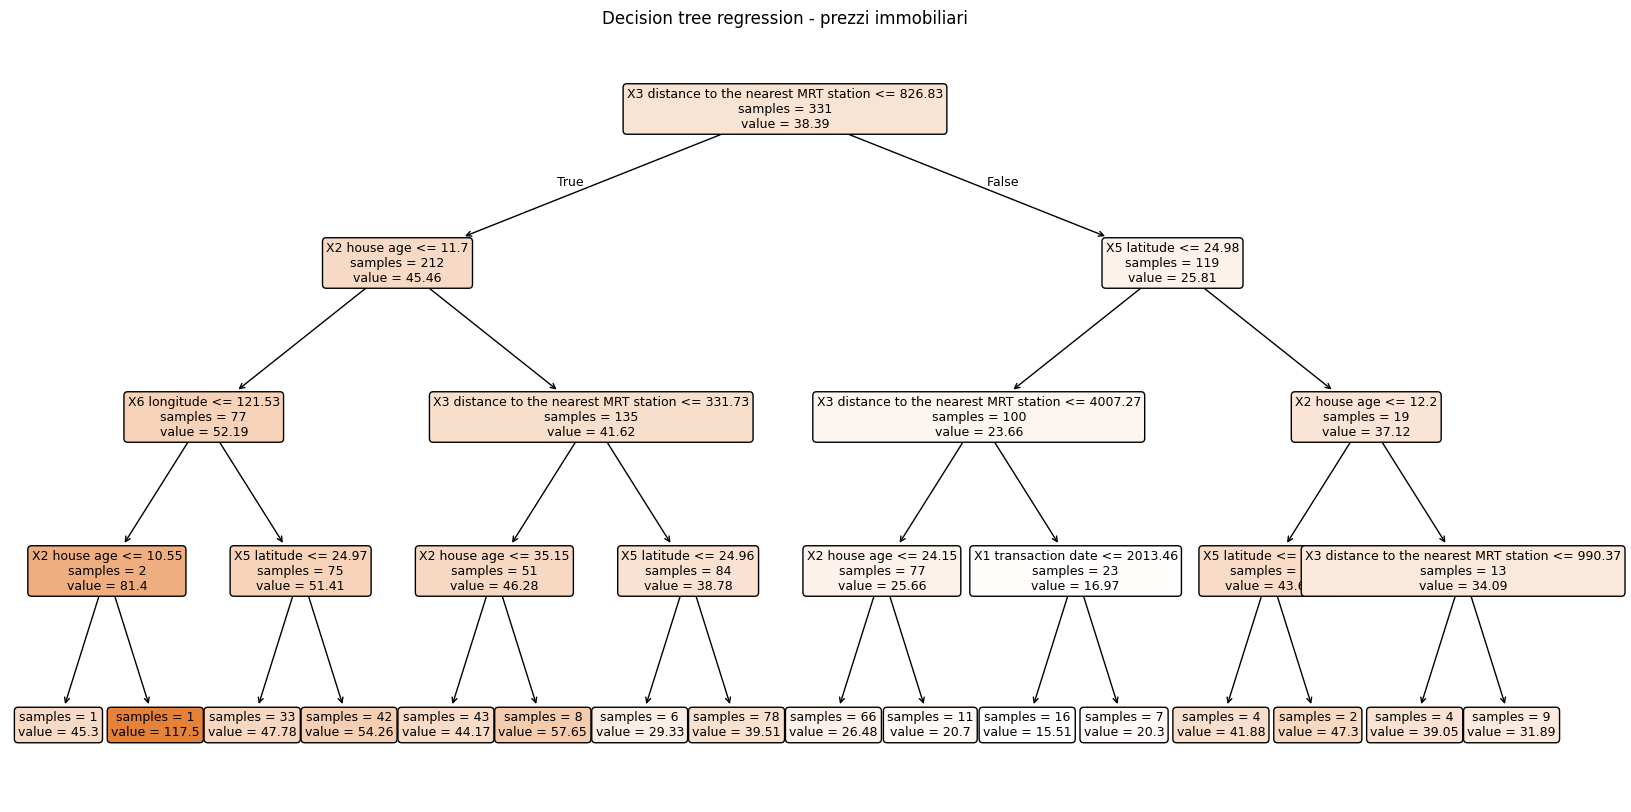

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

#Visualizzazione del Decision Tree Regressor
plt.figure(figsize=(20,10))

plot_tree(
    tree_model.named_steps['model'],
    feature_names=X_train.columns,
    filled=True,
    rounded=True,
    fontsize=9,
    precision=2,
    impurity=False
)
plt.title('Decision tree regression - prezzi immobiliari')
plt.show()

### Interpretazione 3.4 Decision Tree Regressor

Questo modello utilizza distanza dalla MRT come prima variabile per suddividere gli immobili. Nek Training set, i 212 immobili entro circa 826,83 metri dalla MRT presentano un prezzo medio di 45,46 mentre i 119 immobili più lontani hanno un prezzo medio di 25,81.

Nei livelli successivi, modello considera altre caratteristiche, come l'età dell'immobile, la latitudine, longitudine e data della transazione, per suddividere ulteriormente i dati e ottenere previsioni più specifiche.
Oserrvando comunque le foglie finali, alcune contengono una o due osservazioni. Questo indica rischio di overfitting, poiché il modello può adattarsi troppo alle caratteristiche dei dati di training.

Il grafico mostra quindi come l'albero utilizza le caratteristiche degli immobili per prevedere il prezzo, senza dimostrare relazioni causali.


# 4. Ottimizzazione con Cross-Validation

In questa fase, valuto i modelli con cross-validation e cercherò di migliorare le prestazioni dei modelli usando l'ottimizzazione degli iperparametri. Per confrontare bene i risultati dei modelli su diverse suddivisioni dei dati, utilizzo cinque fold sul training set.

Per metrica principale utilizzo **MAE(Mean Absolute Error)**, questo indica quanto la previsione si discostano mediamente dai prezzi reali. Un valore più basso del MAE significa un errore medio minore.

Confrontando l'errore sui dati di training con l'errore sui dati di validazione, mi aiuterà a capire se un modello soffre di **overfitting**. Overfitting si verifica quando un modello si adatta troppo ai dati di training e ha più difficoltà con dati non usati durante l'addestramento.

Il test set invece non utilizzo durante la scelta degli iperparametri, le utilizzerò nella fase 5 per valutare prestazioni finali dei modelli.


### 4.1 Valutazione iniziale con k-fold cross validation

Prima di ottimizzare gli iperparametri, confronto i tre modelli iniziali — Regressione Lineare, Ridge e Decision Tree Regressor — utilizzando gli stessi cinque fold del training set.

Per ciascun modello calcolo il MAE medio sul training set e il MAE medio di validazione. Confronto soprattutto il MAE di validazione, perché permette di valutare le prestazioni su osservazioni non utilizzate per addestrare il modello nel rispettivo fold. Calcolo anche la deviazione standard del MAE di validazione per osservare quanto l'errore varia tra i fold.

Il MAE è espresso nella stessa unità della variabile target: 10.000 NTD per ping. Un valore più basso indica un errore medio inferiore. La differenza tra MAE di training e di validazione può inoltre fornire un'indicazione di un possibile overfitting.

Per Ridge, la standardizzazione rimane all'interno della Pipeline, così viene adattata esclusivamente sui dati di training di ciascun fold. La Regressione Lineare viene valutata come modello di riferimento interpretabile, senza effettuare una ricerca specifica dei suoi iperparametri in questa fase.


In [ ]:
from sklearn.model_selection import KFold,cross_validate
import pandas as pd

#Stessi 5 fold per tutti i modelli
cv= KFold(n_splits=5,shuffle=True,random_state=42)

modelli_iniziali={
    "Regressione Lineare": Linear_model,
    "Regressione Ridge (alpha=1)": ridge_model,
    "Decision Tree Regressor (depth=4)" : tree_model
    }
righe_cv_iniziali= []
for nome, modello in modelli_iniziali.items():
    risultati = cross_validate(
        modello,
        X_train,
        Y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        return_train_score=True
    )
    mae_training = risultati["train_score"]
    mae_validazione = risultati["test_score"]

    righe_cv_iniziali.append({
        "Modello": nome,
        "MAE training medio": -mae_training.mean(),
        "MAE validazione medio": -mae_validazione.mean(),
        "Deviazione standard MAE validazione": mae_validazione.std(ddof=1)
    })
cv_iniziale = pd.DataFrame(righe_cv_iniziali)
display(
    cv_iniziale
    .sort_values("MAE validazione medio")
    .round(3)
    .reset_index(drop=True)
)

,Modello,MAE training medio,MAE validazione medio,Deviazione standard MAE validazione
0,Decision Tree Regressor (depth=4),4.517,6.119,0.646
1,Regressione Lineare,6.324,6.545,0.872
2,Regressione Ridge (alpha=1),6.324,6.546,0.873


### Interpretazione della valutazione iniziale con K-Fold Cross-Validation

Grazie alla tabella che ho creato, ho notato che il Decision Tree inziale ha il MAE di validazione più bassa(6.119). Ciò significa che, tra i tre modelli, questo modello Decision Tree regressor comette in media errori più piccoli sui dati di validazione.

La regressione Lineare e la Ridge hanno più meno i dati più simili con un MAE di 6.545(Regressione Lineare) e 6.546(Ridge). Pertanto, in questa prima valutazione, Ridge non mostra un miglioramento rispetto alla Regressione Lineare.

Ho notato anche che il MAE training del Decision tree è più basso rispetto a quello di validazione. Questo indica che Decisione Tree si adatta bene ai dati di training rispetto ai dati di validazione quindi sarà importante controllare se vi sono segnali di overfitting.



### 4.2 Ottimizzazione degli iperparametri della Ridge
La ridge utilizza una penalizzazione L2 che riduce i valori dei coefficienti del modello. Il grado di penalizzazione dipende dal parametro 'alpha' se aumenta allora la penalizzazione è più forte invece se diminuisce il suo efetto è minore.

Quindi per trovare il valore più adatto di alpha, utilizzo *GridSearchCV*, che prova diversi valori e confronta con cross-validation a cinque fold. Come metrica utilizzo anche qua MAE, cercando il valore che produce l'errore medio di validazione più bassa. Questa ricerca faccio solo sul Training set invece test set rimane separata per la valutazione finale.

Infine, mostro i risultati con una tabella e grafico, cosi posso vedere come cambia il MAE al variare di alpha e quale configurazione dà i risultati migliori tra quelle provate.



Miglior valore di alpha: 0.001
miglior MAE medio di validazione: 6.545


,Alpha,MAE training medio,MAE validazione medio,Deviazione standard MAE validazione
0,0.001,6.324,6.545,0.780
1,0.010,6.324,6.545,0.780
2,0.100,6.324,6.545,0.780
3,1.000,6.324,6.546,0.781
4,10.000,6.334,6.552,0.788
5,100.000,6.538,6.676,0.932
6,1000.000,8.301,8.381,1.145


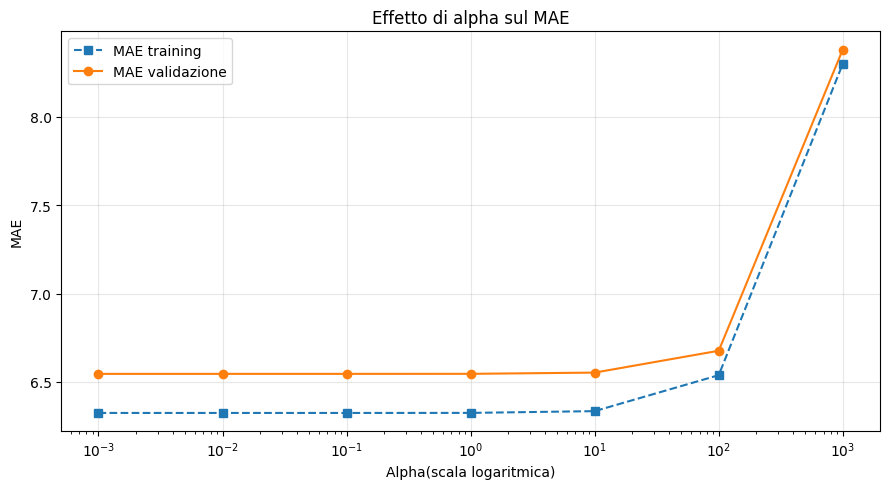

In [ ]:
from sklearn.model_selection import GridSearchCV
import pandas as pd
import matplotlib.pyplot as plt

#Griglia di valori da testare per alpha
param_grid_ridge={
    "model__alpha":[0.001,0.01,0.1,1,10,100,1000]
}
#Ricerca del miglior valore di alpha con 5-fold cross validation
grid_ridge = GridSearchCV(
    estimator= ridge_model,
    param_grid=param_grid_ridge,
    scoring='neg_mean_absolute_error',
    cv=cv,
    n_jobs=-1,
    return_train_score= True
)

grid_ridge.fit(X_train,Y_train)

#Migliorare configurazione individuata
print("Miglior valore di alpha:", grid_ridge.best_params_["model__alpha"])
print("miglior MAE medio di validazione:",round(-grid_ridge.best_score_,3))

#Tabella dei risultati della ricerca
risultati_ridge= pd.DataFrame(grid_ridge.cv_results_)

tabella_ridge= pd.DataFrame({
    "Alpha": risultati_ridge["param_model__alpha"],
    "MAE training medio": -risultati_ridge["mean_train_score"],
    "MAE validazione medio": -risultati_ridge["mean_test_score"],
    "Deviazione standard MAE validazione": risultati_ridge["std_test_score"]
})
display(tabella_ridge.round(3))

#Grafico dell'effetto di alpha sul MAE
plt.figure(figsize=(9,5))
plt.plot(
    tabella_ridge["Alpha"],
    tabella_ridge["MAE training medio"],
    marker="s",
    linestyle="--",
    label="MAE training"
)
plt.plot(
    tabella_ridge["Alpha"],
    tabella_ridge["MAE validazione medio"],
    marker="o",
    label="MAE validazione"

)

plt.xscale("log")
plt.xlabel("Alpha(scala logaritmica)")
plt.ylabel("MAE")
plt.title("Effetto di alpha sul MAE")
plt.legend()
plt.grid(True,alpha=0.3)
plt.tight_layout()
plt.show()


### Interpretazione dei risultati del grafico e tabella
Dalla tabella si vede che il valore **alpha** migliore tra quelli testati è 0.001 con un MAE medio di validazione con 6.545, indica che tra le configurazioni esaminate, questa è quella che ha prodotto l'errore medio più basso sui fold di valutazione.

Dal grafico si osserva che il MAE resta quasi invariato per i valori di alpha compresi tra 0.001 e 10. Se alpha raggiunge 100 l'errore iniza a aumentare e con 1000 l'aumenta è molto più marcato sia nel training set che nella validazione.
Ho scelto alpha 0.001 perchè, quando alpha è troppo alto, la penalizzazione diventa molto forte e può limitare in modo eccessivo i coefficienti del modello. Di conseguenza, la Ridge rischia di non riuscire a rappresentare bene le relazioni presenti nei dati. Quindi, alpha=0.001 è la configurazione migliore tra quelle testate.


### 4.3 Ottimizzazione degli iperparametri del Decision Tree Regressor

Decision Tree Regressor utilizza delle regole per dividere i dati in gruppi e fare previsioni sul prezzo degli immobili. Sua complessità dipende da alcuni iperparametri, che permette di controllare come viene costruito l'albero.


- **max_depth** stabilisce la profondità massima dell'albero.
- **min_samples_split** indica quante osservazioni servono per dividere un nodo.
- **min_samples_leaf** stabilisce il numero minimo di osservazioni che devono rimanere in ogni foglia.

Utilizzo GridSearchCV per trovare una configurazione adatta,MAE come metrica di valutazione. Anche qua ricerca viene fatta sul training set e non sul test set.

Confronto i diversi valori degli iperparametri in base al MAE medio di validazione.
Osservo anche il grafico per capire come cambia l'errore al variare della profondità dell'albero e individuo una configurazione che mi permette di ottenere buone previsioni senza rendere il modello troppo complesso.



Migliori iperparametri: {'model__max_depth': 3, 'model__min_samples_leaf': 15, 'model__min_samples_split': 2}
Miglior MAE medio di validazione: 5.465


,Profondità massima,Minimo campioni per split,Minimo campioni per foglia,MAE training medio,MAE validazione medio,Deviazione standard MAE validazione
0,3,2,15,5.304,5.465,0.817
1,3,5,15,5.304,5.465,0.817
2,3,10,15,5.304,5.465,0.817
3,3,20,15,5.304,5.465,0.817
4,3,20,5,5.237,5.520,0.821
5,3,5,10,5.237,5.520,0.821
6,3,10,10,5.237,5.520,0.821
7,3,20,10,5.237,5.520,0.821
8,3,2,10,5.237,5.520,0.821
9,6,20,5,4.363,5.573,0.600


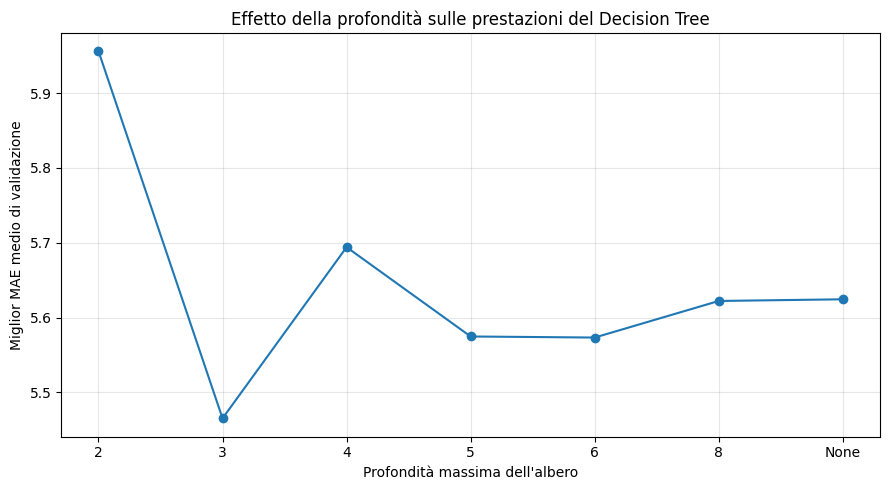

In [ ]:

from sklearn.model_selection import GridSearchCV
import pandas as pd
import matplotlib.pyplot as plt

# Griglia di iperparametri da testare
param_grid_tree = {
    "model__max_depth": [2, 3, 4, 5, 6, 8, None],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 5, 10, 15]
}

# Ricerca della migliore configurazione con 5-fold cross-validation
grid_tree = GridSearchCV(
    estimator=tree_model,
    param_grid=param_grid_tree,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

grid_tree.fit(X_train, Y_train)

# Migliore configurazione individuata
print("Migliori iperparametri:", grid_tree.best_params_)
print("Miglior MAE medio di validazione:", round(-grid_tree.best_score_, 3))

# Tabella dei risultati
risultati_tree = pd.DataFrame(grid_tree.cv_results_)

tabella_tree = pd.DataFrame({
    "Profondità massima": risultati_tree["param_model__max_depth"].astype(str),
    "Minimo campioni per split": risultati_tree["param_model__min_samples_split"].astype(int),
    "Minimo campioni per foglia": risultati_tree["param_model__min_samples_leaf"].astype(int),
    "MAE training medio": -risultati_tree["mean_train_score"],
    "MAE validazione medio": -risultati_tree["mean_test_score"],
    "Deviazione standard MAE validazione": risultati_tree["std_test_score"]
})

# Mostro le 10 configurazioni con MAE di validazione più basso
display(
    tabella_tree
    .sort_values("MAE validazione medio")
    .head(10)
    .round(3)
    .reset_index(drop=True)
)

# Confronto del miglior MAE per ciascuna profondità massima
mae_per_profondita = (
    tabella_tree
    .groupby("Profondità massima")["MAE validazione medio"]
    .min()
    .reindex(["2", "3", "4", "5", "6", "8", "None"])
)

plt.figure(figsize=(9, 5))
plt.plot(
    mae_per_profondita.index,
    mae_per_profondita.values,
    marker="o"
)

plt.xlabel("Profondità massima dell'albero")
plt.ylabel("Miglior MAE medio di validazione")
plt.title("Effetto della profondità sulle prestazioni del Decision Tree")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Interpretazione dell'ottimizzazione del Decision Tree Regressor

Dalla tabella si vede che migliore configurazione del Decision tree ha max_depth=3, min_samples_split=2 e min_samples_leaf=15, con un medio di validazione pari a 5.465. Quindi, questo mi dice che, questo ha ottenuto l'errore medio più basso sui fold di validazione.

- Valore max_depth=3 indica che l'albero ha una profondità di tre livelli
- min_samples_leaf=15 richiede almeno 15 osservazioni in ogni foglia.

Queste osservazioni limitano complessità dell'albero e aiutano a evitare che si adatti troppo ai dati di training.

Invece dal grafico, si nota che profondità 2 produce MAE più alto invece con profondità 3 l'errore diminuisce e raggiunge valore più basso tra profondità complesse.

Per questo motivo, scelgo la configurazione con profondità 3 e almeno 15 osservazioni per foglia. Il MAE training è 5.304, mentre quello di validazione è 5.465.


### 4.4 Confronto dei modelli prima e dopo l'ottimizzazione

In questa sezione confronto le prestazioni iniziali dei tre modelli con quelle ottenute dopo l'ottimizzazione degli iperparametri della Ridge e del Decision Tree Regressor.

Utilizzo il MAE medio di validazione ottenuto con la cross-validation a cinque fold come metrica principale. Confronto anche il MAE di training e la deviazione standard dell'errore di validazione per valutare le differenze tra le prestazioni sui dati di training e quelle sui fold di validazione.

Questo confronto permette di verificare se l'ottimizzazione ha migliorato le prestazioni dei modelli. La selezione rimane basata esclusivamente sul training set e sulla cross-validation; il test set sarà utilizzato soltanto nella Fase 5.


In [ ]:
print(cv_iniziale["Modello"].tolist())

['Regressione Lineare', 'Regressione Ridge (alpha=1)', 'Decision Tree Regressor (depth=4)']


,Modello,MAE training medio,MAE validazione medio
0,Decision Tree ottimizzato,5.304,5.465
1,Decision Tree iniziale (depth=4),4.517,6.119
2,Regressione Lineare iniziale,6.324,6.545
3,Ridge ottimizzata,6.324,6.545
4,Ridge iniziale (alpha=1),6.324,6.546


Migliori parametri Ridge: {'model__alpha': 0.001}
Migliori parametri Decision Tree: {'model__max_depth': 3, 'model__min_samples_leaf': 15, 'model__min_samples_split': 2}


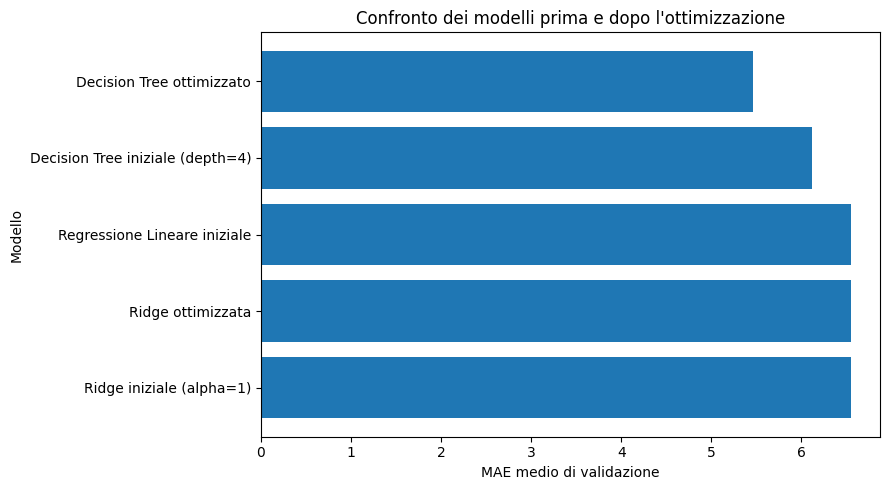

In [ ]:

# Risultati iniziali della cross-validation
iniziali = cv_iniziale.set_index("Modello")

# Tabella di confronto tra modelli iniziali e ottimizzati
confronto_fase4 = pd.DataFrame([
    {
        "Modello": "Regressione Lineare iniziale",
        "MAE training medio": iniziali.loc[
            "Regressione Lineare", "MAE training medio"
        ],
        "MAE validazione medio": iniziali.loc[
            "Regressione Lineare", "MAE validazione medio"
        ]
    },
    {
        "Modello": "Ridge iniziale (alpha=1)",
        "MAE training medio": iniziali.loc[
            "Regressione Ridge (alpha=1)", "MAE training medio"
        ],
        "MAE validazione medio": iniziali.loc[
            "Regressione Ridge (alpha=1)", "MAE validazione medio"
        ]
    },
    {
        "Modello": "Ridge ottimizzata",
        "MAE training medio": -grid_ridge.cv_results_[
            "mean_train_score"
        ][grid_ridge.best_index_],
        "MAE validazione medio": -grid_ridge.best_score_
    },
    {
        "Modello": "Decision Tree iniziale (depth=4)",
        "MAE training medio": iniziali.loc[
            "Decision Tree Regressor (depth=4)", "MAE training medio"
        ],
        "MAE validazione medio": iniziali.loc[
            "Decision Tree Regressor (depth=4)", "MAE validazione medio"
        ]
    },
    {
        "Modello": "Decision Tree ottimizzato",
        "MAE training medio": -grid_tree.cv_results_[
            "mean_train_score"
        ][grid_tree.best_index_],
        "MAE validazione medio": -grid_tree.best_score_
    }
])

# Mostro i risultati dal MAE di validazione più basso
display(
    confronto_fase4
    .sort_values("MAE validazione medio")
    .round(3)
    .reset_index(drop=True)
)

# Stampo i migliori iperparametri
print("Migliori parametri Ridge:", grid_ridge.best_params_)
print("Migliori parametri Decision Tree:", grid_tree.best_params_)

# Grafico di confronto
confronto_ordinato = confronto_fase4.sort_values(
    "MAE validazione medio"
)

plt.figure(figsize=(9, 5))
plt.barh(
    confronto_ordinato["Modello"],
    confronto_ordinato["MAE validazione medio"]
)
plt.xlabel("MAE medio di validazione")
plt.ylabel("Modello")
plt.title("Confronto dei modelli prima e dopo l'ottimizzazione")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


### Interpretazione
Dalla tabella che ho creato, si vede che il Decision tree ottimizzato ha il MAE di validazione più basso, pari a 5.465, rispetto al medio iniziale che aveva un MAE di 6.119 (nella fase 4.1), l'errore è diminuito dopo l'ottimizzazione.
Anche la differenza tra MAE di training(5.304) e validazione(5.465) è più piccola dalla prima. Questo indica una migliore capacità di generalizzazione.

Poi regressione lineare e Ridge ottimizzata hanno quasi uguali risultati, mentre ridge iniziale ha un MAE di 6.546, quindi questo ridge non ha portato un miglioramento.

Per questi motivi, scelgo Decision Tree ottimizzato come modello migliore tra quelli confrontati. Verificherò le sue prestazioni sul test set nel fase 5.


# 5. Valutazione e confronto dei modelli

In questa fase valuto le prestazioni dei modelli sul test set, che non è stato utilizzato durante l'ottimizzazione degli iperparametri. Considero la Regressione Lineare, la Ridge ottimizzata e il Decision Tree Regressor ottimizzato.

Per confrontare le previsioni utilizzo tre metriche: MAE, RMSE e coefficiente di determinazione R². Successivamente, analizzo graficamente le previsioni e i residui per comprendere meglio gli errori dei modelli e valutare la loro capacità di generalizzazione.



## 5.1 Valutazione finale sul test set

Valuto i tre modelli candidati utilizzando le osservazioni del test set, mantenute separate durante la cross-validation e la ricerca degli iperparametri.

Il MAE misura l'errore assoluto medio, mentre il RMSE penalizza maggiormente gli errori più grandi. Il valore di R² indica quanto il modello riesce a spiegare la variabilità dei prezzi osservati rispetto a una previsione basata sulla media del target.

Per MAE e RMSE, valori più bassi indicano prestazioni migliori; per R², valori più elevati indicano una maggiore capacità esplicativa. Utilizzo questi risultati per confrontare le prestazioni finali, senza effettuare ulteriori ottimizzazioni sul test set.


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Modelli candidati per la valutazione finale
modelli_finali = {
    "Regressione Lineare": Linear_model,
    "Ridge ottimizzata": grid_ridge.best_estimator_,
    "Decision Tree ottimizzato": grid_tree.best_estimator_
}

risultati_test = []
previsioni_test = {}

for nome, modello in modelli_finali.items():

    # Addestramento sul training set completo
    modello.fit(X_train, Y_train)

    # Previsioni sul test set
    y_pred = modello.predict(X_test)
    previsioni_test[nome] = y_pred

    # Calcolo delle metriche
    mae = mean_absolute_error(Y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(Y_test, y_pred))
    r2 = r2_score(Y_test, y_pred)

    risultati_test.append({
        "Modello": nome,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    })

# Tabella comparativa delle prestazioni sul test set
tabella_test = pd.DataFrame(risultati_test)

display(
    tabella_test
    .sort_values("MAE")
    .round(3)
    .reset_index(drop=True)
)


,Modello,MAE,RMSE,R²
0,Decision Tree ottimizzato,4.727,6.457,0.751
1,Ridge ottimizzata,5.305,7.315,0.681
2,Regressione Lineare,5.305,7.315,0.681


### Interpretazione dei risultati
Come nella fase 4.4, il Decision Tree ottimizzato aveva ottenuto il MAE medio di validazione più basso, pari a 5.465. Anche sul test set si ottiene i risultati migliori, con un MAE di 4.727, un RMSE di 6.457 e R² di 0.751.

Questi risultati confermano che, tra i modelli confrontati, Decision Tree ha funzionato meglio anche sui dati di test. Invece la Regressione Lineare e Ridge hanno ottenuto risultati quasi identici.





### 5.2
In questa sezione, confronto graficamente le prestazioni dei tre modelli utilizzando un grafico a barre interativo. Dal menu posso scegliere tra MAE, RMSE e R² per osservare le differenze tra i modelli. In questo modo, posso confrontare più facilmente i risultati ottenuti sul test set.

In [ ]:

import plotly.graph_objects as go

nomi = tabella_test["Modello"].tolist()
metriche = ["MAE", "RMSE", "R²"]

fig = go.Figure()

for metrica in metriche:
    valori = tabella_test[metrica].astype(float).tolist()

    fig.add_bar(
        x=valori,
        y=nomi,
        orientation="h",
        name=metrica,
        text=[round(v, 3) for v in valori],
        textposition="outside",
        visible=(metrica == "MAE")
    )

pulsanti = []

for i, metrica in enumerate(metriche):
    visibili = [j == i for j in range(len(metriche))]
    criterio = "più alto è meglio" if metrica == "R²" else "più basso è meglio"

    pulsanti.append(dict(
        label=metrica,
        method="update",
        args=[
            {"visible": visibili},
            {
                "title": f"Confronto dei modelli — {metrica}",
                "xaxis": {"title": f"{metrica} ({criterio})"}
            }
        ]
    ))

fig.update_layout(
    title="Confronto dei modelli — MAE",
    xaxis_title="MAE (più basso è meglio)",
    yaxis_title="Modello",
    updatemenus=[dict(buttons=pulsanti)],
    height=400
)

fig.show()


### Interpretazione 5.2
Anche da questo grafico, si vede che il Decision Tree ottimizzato ha il MAE più basso(con l'errore medio assoluto medio).
La ridge ottimizzata e Regressione Lineare hanno valori più alti e molto simili tra loro.

Questa conferma quindi, la tabella 5.1 il decision tree ha ottenuto la prestazione migliori sul test set.

### 5.3
In questa sezione, confronto i prezzi reali con quelli previsti dai tre modelli attraverso grafici a dispersione.
La linea rossa trattegiata rappresenta la situazione ideale, in cui il prezzo previsto con quello reale. Più i punti sono vicini alla linea, più le previsioni sono accurate.

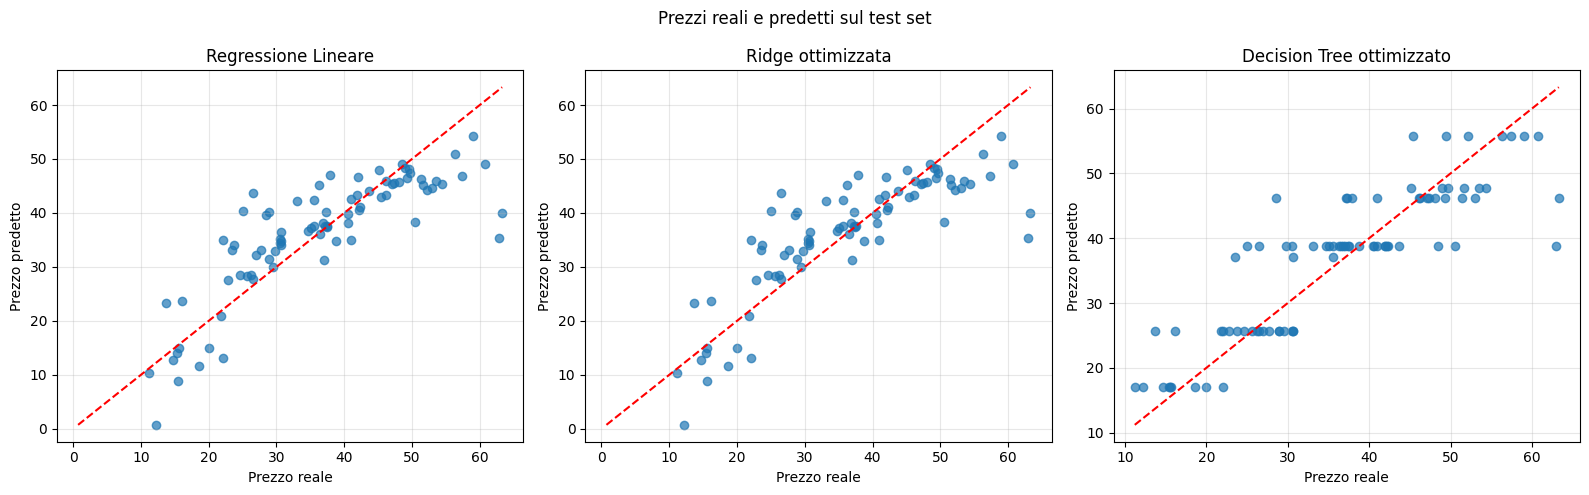

In [ ]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1,3, figsize=(16,5))
for ax, (nome,y_pred) in zip(axes,previsioni_test.items()):
  ax.scatter(Y_test,y_pred,alpha=0.7)

  minimo= min(Y_test.min(),y_pred.min())
  massimo= max(Y_test.max(),y_pred.max())

  ax.plot([minimo,massimo],[minimo,massimo],"r--")
  ax.set_title(nome)
  ax.set_xlabel("Prezzo reale")
  ax.set_ylabel("Prezzo predetto")
  ax.grid(alpha=0.3)

fig.suptitle("Prezzi reali e predetti sul test set")
plt.tight_layout()
plt.show()


### Interpretazione
Nei grafici, si nota bene che la Regressione Lineare e Ridge hanno un andamento molto simile, con diversi punti vicini alla linea rossa.

Il decision Tree presenta invece previsioni più distribuite su alcuni livelli di prezzo, perchè restituisce valori previsti ripetuti.

Comunque, il Decision Tree ha buone prestazioni come confermato dai risultati della fase 5.1.
I grafici, però di osservare anche le differenze tra i modelli e gli errori nelle singole previsioni.

### 5.4
In questa fase, analizzo i residui dei tre modelli per capire meglio gli errori delle previsioni.

Utilizzerò due tipi di grafici:
- Grafico dei residui rispetto ai prezzi predetti
- istogramma della distribuzione dei residui.

La linea rossa trateggiata indica il valore zero, cioè il punto in cui la previsioni coincide con il prezzo reale.

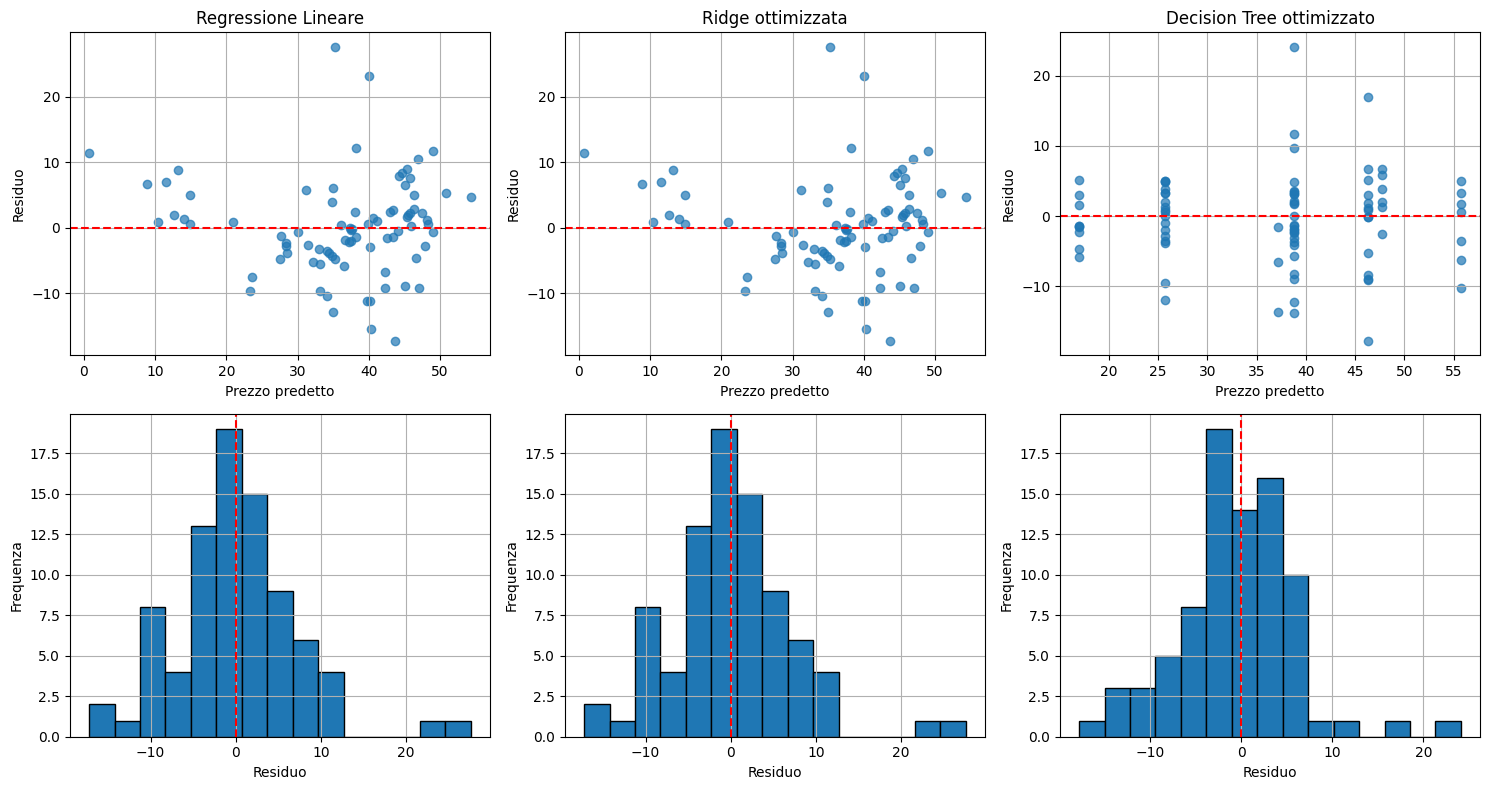

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig,axes = plt.subplots(2,3,figsize=(15,8))
for i, (nome,y_pred) in enumerate(previsioni_test.items()):
  residuali = Y_test - y_pred

  #Grafico dei residui
  axes[0,i].scatter(y_pred,residuali,alpha=0.7)
  axes[0,i].axhline(0,color="red",linestyle="--")
  axes[0,i].set_title(nome)
  axes[0,i].set_xlabel("Prezzo predetto")
  axes[0,i].set_ylabel("Residuo")
  axes[0,i].grid()

  #Istogramma
  axes[1,i].hist(residuali,bins=15,edgecolor="black")
  axes[1,i].axvline(0,color="red",linestyle="--")
  axes[1,i].set_xlabel("Residuo")
  axes[1,i].set_ylabel("Frequenza")
  axes[1,i].grid()
plt.tight_layout()
plt.show()

### Interpretazione 5.4
Dai grafici che ho creato, noto che i residui sono distribuiti intorno allo zero, anche se sono presenti alcuni errori più grandi.

Posso dire che nel decision tree i residui sono raggruppati in corrispondenza di alcuni prezzi predetti.

Dopo aver confrontato le prestazioni dei modelli e analizzato i loro errori, nella fase successiva passo all'analisi esplorativa interattiva dei dati. Questo mi permette di osservare bene le variabili del dataset e di esplorare la relazione tra caratteristiche delle abitazioni e loro prezzo.




# 6. Visualizzazione interattiva dei dati
In questa fase, creo un grafico a dispersione interattivo per esplorare la relazione tra il prezzo degli immobili e sei variabili esplicative.
Attraverso un menu posso scegliere quale variabile analizzare, mentre con slide posso selezionare l'intervallo di prezzo da visualizzare. Il grafico si aggiorna in base di scelta, permettendomi di osservare meglio i dati e le possibili relazioni tra le variabili.

In [ ]:

import ipywidgets as widgets
import plotly.express as px
from IPython.display import display

# Variabili disponibili per l'analisi
variabili = [
    ("Data della transazione", "X1 transaction date"),
    ("Età dell'immobile", "X2 house age"),
    ("Distanza dalla MRT", "X3 distance to the nearest MRT station"),
    ("Negozi di prossimità", "X4 number of convenience stores"),
    ("Latitudine", "X5 latitude"),
    ("Longitudine", "X6 longitude")
]

target = "Y house price of unit area"

etichette = {
    "X1 transaction date": "Data della transazione (anno frazionario)",
    "X2 house age": "Età dell'immobile (anni)",
    "X3 distance to the nearest MRT station": "Distanza dalla MRT (metri)",
    "X4 number of convenience stores": "Numero di negozi",
    "X5 latitude": "Latitudine (gradi)",
    "X6 longitude": "Longitudine (gradi)",
    target: "Prezzo (10.000 NTD per ping)"
}

# Controlli interattivi
selettore = widgets.Dropdown(
    options=variabili,
    value="X3 distance to the nearest MRT station",
    description="Variabile:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="95%")
)

filtro_prezzo = widgets.FloatRangeSlider(
    value=(float(df[target].min()), float(df[target].max())),
    min=float(df[target].min()),
    max=float(df[target].max()),
    step=1.0,
    description="Intervallo prezzo:",
    readout_format=".1f",
    continuous_update=False,
    style={"description_width": "initial"},
    layout=widgets.Layout(width="95%")
)

# Aggiornamento del grafico in base alle selezioni
def aggiorna_grafico(variabile, intervallo_prezzo):
    dati = df[df[target].between(
        intervallo_prezzo[0], intervallo_prezzo[1]
    )]

    if dati.empty:
        print("Nessuna osservazione nell'intervallo selezionato.")
        return

    fig = px.scatter(
        dati,
        x=variabile,
        y=target,
        hover_data=["X2 house age",
                    "X3 distance to the nearest MRT station"],
        labels=etichette,
        title=f"Prezzo immobiliare in funzione di {etichette[variabile]}"
    )

    fig.update_layout(height=500)
    display(fig)

controlli = widgets.VBox([selettore, filtro_prezzo])

grafico = widgets.interactive_output(
    aggiorna_grafico,
    {
        "variabile": selettore,
        "intervallo_prezzo": filtro_prezzo
    }
)

display(controlli, grafico)


Output()

### Interpretazione
Visualizzazione interattiva mi permette di esplorare il dataset in modo più flessibile, scegliendo volta in volta la variabile da confrontare con il prezzo e modificando l'intervallo dei prezzi.

Attraverso questo, posso osservare come distribuiscono le osservazioni e individuare eventuali tendenze o differenze tra loro.

Questa analisi è esplorativa perché mi permette di osservare le relazioni tra variabili, ma non dimostra che una caratteristica causa un aumento o diminuzione. Nella fase successiva utilizzo il modello migliore per creare uno strumento che mi permette di ottenere previsioni delle caratteristiche di un immobile.


# 7. Interfaccia grafica per la previsione del prezzo

In questa fase realizzo un'interfaccia interattiva che permette di inserire le caratteristiche di un immobile e ottenere una previsione del prezzo unitario.

Utilizzo il Decision Tree Regressor ottimizzato nella Fase 4, che ha ottenuto le migliori prestazioni tra i modelli confrontati sul test set. I valori inseriti vengono organizzati nello stesso ordine delle variabili utilizzate durante l'addestramento.

I controlli limitano gli input agli intervalli osservati nel training set e il codice verifica che i valori siano validi prima di effettuare la previsione. Il risultato viene espresso in 10.000 NTD per ping, coerentemente con l'unità della variabile target.


In [ ]:

import ipywidgets as widgets
import numpy as np
import pandas as pd

# Modello selezionato e ottimizzato
modello_finale = grid_tree.best_estimator_

# Creazione di uno slider con i limiti del training set
def crea_slider(colonna, descrizione, passo, formato=".2f"):
    return widgets.FloatSlider(
        value=float(X_train[colonna].median()),
        min=float(X_train[colonna].min()),
        max=float(X_train[colonna].max()),
        step=passo,
        description=descrizione,
        readout_format=formato,
        continuous_update=False,
        style={"description_width": "initial"},
        layout=widgets.Layout(width="95%")
    )

data = crea_slider("X1 transaction date", "Data (anno frazionario):", 0.01, ".3f")
eta = crea_slider("X2 house age", "Età (anni):", 1, ".1f")
distanza = crea_slider("X3 distance to the nearest MRT station", "Distanza MRT (m):", 25, ".1f")

negozi = widgets.IntSlider(
    value=int(round(X_train["X4 number of convenience stores"].median())),
    min=int(X_train["X4 number of convenience stores"].min()),
    max=int(X_train["X4 number of convenience stores"].max()),
    step=1,
    description="Negozi di prossimità:",
    continuous_update=False,
    style={"description_width": "initial"},
    layout=widgets.Layout(width="95%")
)

latitudine = crea_slider("X5 latitude", "Latitudine:", 0.0001, ".4f")
longitudine = crea_slider("X6 longitude", "Longitudine:", 0.0001, ".4f")

# Calcolo della previsione
def prevedi_prezzo(data, eta, distanza, negozi, latitudine, longitudine):

    valori = {
        "X1 transaction date": data,
        "X2 house age": eta,
        "X3 distance to the nearest MRT station": distanza,
        "X4 number of convenience stores": negozi,
        "X5 latitude": latitudine,
        "X6 longitude": longitudine
    }

    input_immobile = pd.DataFrame(
        [valori],
        columns=X_train.columns
    )

    # Controllo di validità degli input
    for colonna in X_train.columns:
        valore = float(input_immobile.iloc[0][colonna])

        if not np.isfinite(valore):
            print("Errore: inserire soltanto valori numerici validi.")
            return

        if not X_train[colonna].min() <= valore <= X_train[colonna].max():
            print(f"Errore: il valore di {colonna} è fuori dall'intervallo consentito.")
            return

    prezzo = float(modello_finale.predict(input_immobile)[0])

    print(f"Prezzo unitario previsto: {prezzo:.2f} × 10.000 NTD per ping")
    print(f"Equivalente in NTD per ping: {prezzo * 10000:,.0f} NTD")

# Interfaccia interattiva
widgets.interact(
    prevedi_prezzo,
    data=data,
    eta=eta,
    distanza=distanza,
    negozi=negozi,
    latitudine=latitudine,
    longitudine=longitudine
)


interactive(children=(FloatSlider(value=2013.1666667, continuous_update=False, description='Data (anno frazion…

<function __main__.prevedi_prezzo(data, eta, distanza, negozi, latitudine, longitudine)>

### Interpretazione
L'interfaccia permette di modificare le caratteristiche dell'immobile e osservare come cambia il prezzo previsto dal Decision Tree ottimizzato. In questo modo, il modello può essere utilizzato in modo interattivo, senza dover inserire manualmente i dati nel codice ogni volta.

La previsione dipende dai valori selezionati e dalle relazioni apprese dal modello durante l'addestramento. Il risultato è una stima del prezzo unitario, non il prezzo esatto di un immobile reale. Questa fase conclude il progetto con un'applicazione pratica del modello scelto e valutato nelle fasi precedenti.

## Conclusione

In questo progetto ho analizzato un dataset relativo ai prezzi degli immobili e ho studiato la relazione tra il prezzo e le diverse caratteristiche delle abitazioni.

Dopo aver esplorato e preparato i dati, ho addestrato e confrontato tre modelli di Machine Learning: Regressione Lineare, Ridge e Decision Tree Regressor. Ho valutato le loro prestazioni utilizzando MAE, RMSE e R², analizzando anche i grafici delle previsioni e dei residui.

Il Decision Tree ottimizzato ha ottenuto i risultati migliori sul test set. Infine, ho creato una visualizzazione interattiva per esplorare i dati e un'interfaccia che permette di inserire le caratteristiche di un immobile e ottenere una previsione del prezzo.

Questo progetto mi ha permesso di applicare le principali fasi di un progetto di Machine Learning, dall'analisi dei dati alla valutazione dei modelli, fino alla realizzazione di uno strumento interattivo per le previsioni.